In [1]:
import pandas as pd
import numpy as np

In [2]:
data = pd.read_csv(r"X:\PROJETS\PYTHON\detection_fraude_autoencoder\backend\data\PS_20174392719_1491204439457_log.csv")

In [3]:
data

,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,9839.64,C1231006815,170136.00,160296.36,M1979787155,0.00,0.00,0,0
1,1,PAYMENT,1864.28,C1666544295,21249.00,19384.72,M2044282225,0.00,0.00,0,0
2,1,TRANSFER,181.00,C1305486145,181.00,0.00,C553264065,0.00,0.00,1,0
3,1,CASH_OUT,181.00,C840083671,181.00,0.00,C38997010,21182.00,0.00,1,0
4,1,PAYMENT,11668.14,C2048537720,41554.00,29885.86,M1230701703,0.00,0.00,0,0
...,...,...,...,...,...,...,...,...,...,...,...
6362615,743,CASH_OUT,339682.13,C786484425,339682.13,0.00,C776919290,0.00,339682.13,1,0
6362616,743,TRANSFER,6311409.28,C1529008245,6311409.28,0.00,C1881841831,0.00,0.00,1,0
6362617,743,CASH_OUT,6311409.28,C1162922333,6311409.28,0.00,C1365125890,68488.84,6379898.11,1,0
6362618,743,TRANSFER,850002.52,C1685995037,850002.52,0.00,C2080388513,0.00,0.00,1,0


In [4]:
data.shape

(6362620, 11)

In [5]:
data.dtypes

step                int64
type               object
amount            float64
nameOrig           object
oldbalanceOrg     float64
newbalanceOrig    float64
nameDest           object
oldbalanceDest    float64
newbalanceDest    float64
isFraud             int64
isFlaggedFraud      int64
dtype: object

In [6]:
data["isFraud"].value_counts()

isFraud
0    6354407
1       8213
Name: count, dtype: int64

In [7]:
data["isFraud"].value_counts(normalize=True) * 100

isFraud
0    99.870918
1     0.129082
Name: proportion, dtype: float64

In [8]:
data.isna().sum()

step              0
type              0
amount            0
nameOrig          0
oldbalanceOrg     0
newbalanceOrig    0
nameDest          0
oldbalanceDest    0
newbalanceDest    0
isFraud           0
isFlaggedFraud    0
dtype: int64

In [9]:
data.duplicated().sum()

0

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

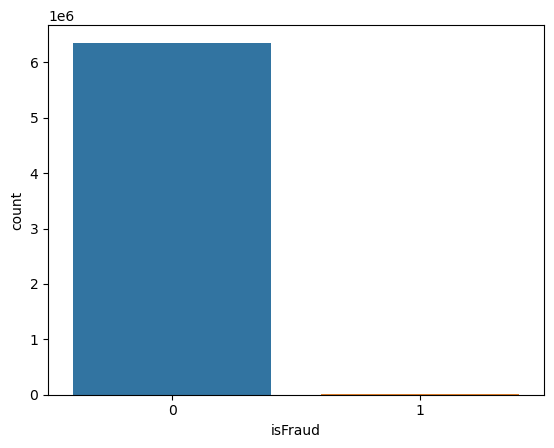

In [11]:
fig,axes = plt.subplots()
sns.countplot(data,x="isFraud")
plt.show()

In [18]:
pd.crosstab(data["type"],data["isFraud"],normalize="index") * 100

isFraud,0,1
type,,
CASH_IN,100.000000,0.000000
CASH_OUT,99.816045,0.183955
DEBIT,100.000000,0.000000
PAYMENT,100.000000,0.000000
TRANSFER,99.231201,0.768799


# filtrage des lignes en fonction de type de transactions ayant un % de transactions frauduleuses

In [23]:
df_filtered = data[data["type"].isin(['CASH_OUT','TRANSFER'])]

In [24]:
df_filtered.shape

(2770409, 11)

# feature selection

In [25]:
cols_to_drop = ["isFraud", "isFlaggedFraud", "nameOrig", "nameDest"]
df_selected = df_filtered.drop(columns=cols_to_drop).copy()

# Encodage binaire de type : 1 pour TRANSFER, 0 pour CASH_OUT
df_selected["is_transfer"] = (df_selected["type"] == "TRANSFER").astype(int)
df_selected = df_selected.drop(columns=["type"])

print(df_selected.columns.tolist())
print(df_selected.shape)

['step', 'amount', 'oldbalanceOrg', 'newbalanceOrig', 'oldbalanceDest', 'newbalanceDest', 'is_transfer']
(2770409, 7)


# normalisation des  et separation en train/val/test

In [27]:
import numpy as np
from sklearn.preprocessing import StandardScaler

log_cols = [
    "amount",
    "oldbalanceOrg",
    "newbalanceOrig",
    "oldbalanceDest",
    "newbalanceDest",
]
feature_cols = ["step"] + log_cols + ["is_transfer"]

# Récupération alignée de isFraud depuis df_filtered
is_fraud = df_filtered.loc[df_selected.index, "isFraud"]

# 1. Découpage temporel avec 'step' (70% train, 15% val, 15% test)
q70, q85 = df_selected["step"].quantile([0.70, 0.85])

train_df = df_selected[
    (df_selected["step"] <= q70) & (is_fraud == 0)
].copy()
val_df = df_selected[
    (df_selected["step"] > q70) & (df_selected["step"] <= q85)
].copy()
test_df = df_selected[df_selected["step"] > q85].copy()

# 2. log1p sur chaque bloc
for df_part in [train_df, val_df, test_df]:
  for col in log_cols:
    df_part[col] = np.log1p(df_part[col].clip(lower=0))

# 3. StandardScaler fitté UNIQUEMENT sur train_df (transactions normales)
scaler = StandardScaler()
cols_to_scale = ["step"] + log_cols

X_train = train_df[feature_cols].copy()
X_val = val_df[feature_cols].copy()
X_test = test_df[feature_cols].copy()

X_train[cols_to_scale] = scaler.fit_transform(X_train[cols_to_scale])
X_val[cols_to_scale] = scaler.transform(X_val[cols_to_scale])
X_test[cols_to_scale] = scaler.transform(X_test[cols_to_scale])

y_val = df_filtered.loc[val_df.index, "isFraud"].to_numpy()
y_test = df_filtered.loc[test_df.index, "isFraud"].to_numpy()

# transformation en tenseur

In [28]:
import torch
from torch.utils.data import DataLoader, TensorDataset

# 1. Conversion DataFrame -> NumPy float32 -> Tenseurs PyTorch
X_train_tensor = torch.tensor(X_train.to_numpy(), dtype=torch.float32)
X_val_tensor = torch.tensor(X_val.to_numpy(), dtype=torch.float32)
X_test_tensor = torch.tensor(X_test.to_numpy(), dtype=torch.float32)

# 2. Datasets (pour l'Autoencodeur, l'entrée sert aussi de cible de reconstruction)
train_dataset = TensorDataset(X_train_tensor, X_train_tensor)
val_dataset = TensorDataset(X_val_tensor)
test_dataset = TensorDataset(X_test_tensor)

# 3. DataLoaders en mini-batchs
batch_size = 512
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

# Module AutoEncodeur

In [35]:
import torch.nn as nn
import torch.optim as optim

In [47]:
class AutoEncoder(nn.Module):

  def __init__(self, input_dim, latent_dim=3):
    super().__init__()
    self.encoder = nn.Sequential(
        nn.Linear(input_dim, 16),
        nn.ReLU(),
        nn.Linear(16, 4),
        nn.ReLU(),
        nn.Linear(4, latent_dim),
    )
    self.decoder = nn.Sequential(
        nn.Linear(latent_dim, 4),
        nn.ReLU(),
        nn.Linear(4, 16),
        nn.ReLU(),
        nn.Linear(16, input_dim),
    )

  def forward(self, x):
    latent = self.encoder(x)
    decoded = self.decoder(latent)
    return decoded

# Boucle d'entrainement

In [48]:
input_dim = X_train.shape[1]
model = AutoEncoder(input_dim=input_dim, latent_dim=3)

In [49]:
criterion = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=1e-3)

epochs = 10

for epoch in range(epochs):
  model.train()
  train_loss = 0.0

  for x_batch, target_batch in train_loader:
    optimizer.zero_grad()
    recon = model(x_batch)
    loss = criterion(recon, target_batch)
    loss.backward()
    optimizer.step()

    train_loss += loss.item() * x_batch.size(0)

  train_loss /= len(train_loader.dataset)

  model.eval()
  val_loss = 0.0

  with torch.no_grad():
    for (x_batch,) in val_loader:
      recon = model(x_batch)
      loss = criterion(recon, x_batch)
      val_loss += loss.item() * x_batch.size(0)

  val_loss /= len(val_loader.dataset)

  print(
      f"Epoch [{epoch + 1}/{epochs}] - Train Loss: {train_loss:.6f} - Val"
      f" Loss: {val_loss:.6f}"
  )

Epoch [1/10] - Train Loss: 0.222191 - Val Loss: 0.207266
Epoch [2/10] - Train Loss: 0.121136 - Val Loss: 0.165185
Epoch [3/10] - Train Loss: 0.107579 - Val Loss: 0.150310
Epoch [4/10] - Train Loss: 0.102034 - Val Loss: 0.166426
Epoch [5/10] - Train Loss: 0.099636 - Val Loss: 0.156835
Epoch [6/10] - Train Loss: 0.098405 - Val Loss: 0.163829
Epoch [7/10] - Train Loss: 0.097605 - Val Loss: 0.156157
Epoch [8/10] - Train Loss: 0.096954 - Val Loss: 0.146653
Epoch [9/10] - Train Loss: 0.096431 - Val Loss: 0.157690
Epoch [10/10] - Train Loss: 0.096003 - Val Loss: 0.163499


# évaluation du modele

In [53]:
model.eval()
val_errors = []

with torch.no_grad():
  for (x_batch,) in val_loader:
    recon = model(x_batch)
    row_mse = torch.mean((x_batch - recon) ** 2, dim=1)
    val_errors.append(row_mse)

val_errors = torch.cat(val_errors).numpy()
val_errors

array([0.07819431, 0.14799237, 0.22383901, ..., 0.0930435 , 0.17478833,
       0.6683101 ], dtype=float32)

In [54]:
normal_errors = val_errors[y_val == 0]
fraud_errors = val_errors[y_val == 1]

print("Normal (y_val == 0) - count:", len(normal_errors))
print(
    "Normal - median:",
    np.median(normal_errors),
    "| mean:",
    np.mean(normal_errors),
    "| p95:",
    np.percentile(normal_errors, 95),
)

print("\nFraude (y_val == 1) - count:", len(fraud_errors))
print(
    "Fraude - median:",
    np.median(fraud_errors),
    "| mean:",
    np.mean(fraud_errors),
    "| p95:",
    np.percentile(fraud_errors, 95),
)

Normal (y_val == 0) - count: 409877
Normal - median: 0.10461513 | mean: 0.16238366 | p95: 0.5444151639938353

Fraude (y_val == 1) - count: 560
Fraude - median: 1.4398103 | mean: 0.97949123 | p95: 1.9522528409957884


In [55]:
from sklearn.metrics import roc_auc_score, average_precision_score

roc_auc = roc_auc_score(y_val, val_errors)
pr_auc = average_precision_score(y_val, val_errors)

print("ROC-AUC (val):", roc_auc)
print("PR-AUC  (val):", pr_auc)

ROC-AUC (val): 0.8492783919670676
PR-AUC  (val): 0.12223081010407935


In [56]:
from sklearn.metrics import precision_score, recall_score, confusion_matrix

thresholds = [0.5, 1.0, 1.4, 1.8]

for tau in thresholds:
  y_pred = (val_errors > tau).astype(int)
  tn, fp, fn, tp = confusion_matrix(y_val, y_pred).ravel()
  prec = precision_score(y_val, y_pred, zero_division=0)
  rec = recall_score(y_val, y_pred, zero_division=0)

  print(
      f"tau={tau:.2f} | TP={tp:3d}/{560} | FP={fp:5d} | FN={fn:3d} |"
      f" Recall={rec:.3f} | Precision={prec:.3f}"
  )

tau=0.50 | TP=286/560 | FP=26005 | FN=274 | Recall=0.511 | Precision=0.011
tau=1.00 | TP=283/560 | FP= 2127 | FN=277 | Recall=0.505 | Precision=0.117
tau=1.40 | TP=281/560 | FP=  763 | FN=279 | Recall=0.502 | Precision=0.269
tau=1.80 | TP=108/560 | FP=  337 | FN=452 | Recall=0.193 | Precision=0.243


In [57]:
from sklearn.metrics import precision_score, recall_score, confusion_matrix

thresholds = [0.5, 1.0, 1.4, 1.8]

for tau in thresholds:
  y_pred = (val_errors > tau).astype(int)
  tn, fp, fn, tp = confusion_matrix(y_val, y_pred).ravel()
  prec = precision_score(y_val, y_pred, zero_division=0)
  rec = recall_score(y_val, y_pred, zero_division=0)

  print(
      f"tau={tau:.2f} | TP={tp:3d}/{560} | FP={fp:5d} | FN={fn:3d} |"
      f" Recall={rec:.3f} | Precision={prec:.3f}"
  )

tau=0.50 | TP=286/560 | FP=26005 | FN=274 | Recall=0.511 | Precision=0.011
tau=1.00 | TP=283/560 | FP= 2127 | FN=277 | Recall=0.505 | Precision=0.117
tau=1.40 | TP=281/560 | FP=  763 | FN=279 | Recall=0.502 | Precision=0.269
tau=1.80 | TP=108/560 | FP=  337 | FN=452 | Recall=0.193 | Precision=0.243


In [58]:
from sklearn.metrics import confusion_matrix, f1_score, precision_score, recall_score

thresholds = [1.2, 1.3, 1.4, 1.5]
total_frauds = int((y_val == 1).sum())

for tau in thresholds:
  y_pred = (val_errors > tau).astype(int)
  tn, fp, fn, tp = confusion_matrix(y_val, y_pred).ravel()
  prec = precision_score(y_val, y_pred, zero_division=0)
  rec = recall_score(y_val, y_pred, zero_division=0)
  f1 = f1_score(y_val, y_pred, zero_division=0)

  print(
      f"tau={tau:.2f} | TP={tp:3d}/{total_frauds} | FP={fp:4d} | FN={fn:3d} |"
      f" Recall={rec:.3f} | Precision={prec:.3f} | F1={f1:.3f}"
  )

tau=1.20 | TP=282/560 | FP=1254 | FN=278 | Recall=0.504 | Precision=0.184 | F1=0.269
tau=1.30 | TP=282/560 | FP= 966 | FN=278 | Recall=0.504 | Precision=0.226 | F1=0.312
tau=1.40 | TP=281/560 | FP= 763 | FN=279 | Recall=0.502 | Precision=0.269 | F1=0.350
tau=1.50 | TP=254/560 | FP= 592 | FN=306 | Recall=0.454 | Precision=0.300 | F1=0.361


In [59]:
from sklearn.metrics import (
    average_precision_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)

model.eval()
test_errors = []

with torch.no_grad():
  for (x_batch,) in test_loader:
    recon = model(x_batch)
    row_mse = torch.mean((x_batch - recon) ** 2, dim=1)
    test_errors.append(row_mse)

test_errors = torch.cat(test_errors).numpy()
best_tau = 1.40

y_test_pred = (test_errors > best_tau).astype(int)
tn, fp, fn, tp = confusion_matrix(y_test, y_test_pred).ravel()

print("Test ROC-AUC:", roc_auc_score(y_test, test_errors))
print("Test PR-AUC :", average_precision_score(y_test, test_errors))
print(
    f"tau={best_tau:.2f} | TP={tp} | FP={fp} | FN={fn} |"
    f" Recall={recall_score(y_test, y_test_pred, zero_division=0):.3f} |"
    f" Precision={precision_score(y_test, y_test_pred, zero_division=0):.3f} |"
    f" F1={f1_score(y_test, y_test_pred, zero_division=0):.3f}"
)

Test ROC-AUC: 0.8507067298479616
Test PR-AUC : 0.2244590369238152
tau=1.40 | TP=2981 | FP=89230 | FN=1029 | Recall=0.743 | Precision=0.032 | F1=0.062


# sauvegarde du modele

In [60]:
import json
from pathlib import Path
import torch

# Dossier déjà existant : backend\models
output_dir = Path(r"X:\PROJETS\PYTHON\detection_fraude_autoencoder\backend\models")
assert output_dir.exists(), f"Dossier introuvable : {output_dir}"

# 1. Récupérer un batch d'exemple réel (même device que le modèle)
device = next(model.parameters()).device
sample_batch = next(iter(val_loader))[0][:1].to(device)

# 2. Tracer le modèle en mode évaluation
model.eval()
with torch.no_grad():
  traced_model = torch.jit.trace(model, sample_batch)
  max_diff = torch.max(torch.abs(model(sample_batch) - traced_model(sample_batch))).item()

traced_path = output_dir / "autoencoder_traced.pt"
traced_model.save(str(traced_path))

# 3. Sauvegarder le seuil et les métriques clés à côté
config = {
    "model_file": traced_path.name,
    "threshold_tau": 1.40,
    "input_features": int(sample_batch.shape[1]),
    "metrics": {
        "val": {
            "roc_auc": 0.8492783919670676,
            "pr_auc": 0.12223081010407935,
            "tp": 281,
            "fp": 763,
            "fn": 279,
            "recall": 0.502,
            "precision": 0.269,
            "f1": 0.350,
        },
        "test": {
            "roc_auc": 0.8507067298479616,
            "pr_auc": 0.2244590369238152,
            "tp": 2981,
            "fp": 89230,
            "fn": 1029,
            "recall": 0.743,
            "precision": 0.032,
            "f1": 0.062,
        },
    },
}

config_path = output_dir / "model_config.json"
with open(config_path, "w", encoding="utf-8") as f:
  json.dump(config, f, indent=2)

print("Modèle tracé sauvegardé :", traced_path)
print("Config sauvegardée       :", config_path)
print("Écart max trace vs model :", max_diff)

Modèle tracé sauvegardé : X:\PROJETS\PYTHON\detection_fraude_autoencoder\backend\models\autoencoder_traced.pt
Config sauvegardée       : X:\PROJETS\PYTHON\detection_fraude_autoencoder\backend\models\model_config.json
Écart max trace vs model : 0.0
